# Imports

In [ ]:
import pandas as pd
from retriever import retrieve
from tqdm import tqdm
import os
from dotenv import load_dotenv
from groq import RateLimitError,APIError
import json
import groq
import re
import time
import numpy as np
from neo4j.exceptions import ServiceUnavailable, SessionExpired, TransientError
import matplotlib.pyplot as plt

In [2]:
load_dotenv()
GROQ_API_KEYS=os.getenv("GROQ_API_KEYS")
#GROQ_API_KEYS

In [3]:
groqs=GROQ_API_KEYS.split(',')
#(groqs)

# TeleQnA

In [126]:
df = pd.read_json(r"E:\Vignesh\VIT\Project 1\TelecomRAG\Datasets\Telecom\teleqna_3gpp_questions.json")
df.head()

,question_id,question,option 1,option 2,option 3,option 4,option 5,category
0,question 0,What is the purpose of the Nmfaf_3daDataManage...,To configure the MFAF to map data or analytics...,To configure the MFAF to stop mapping data or ...,To supply data or analytics from the MFAF to n...,To fetch data or analytics from the MFAF based...,,Standards specifications
1,question 4,How does a supporting UE attach to the same co...,It requests the core network node to remember ...,It uses information stored in the UE when it w...,It relies on the SIM/USIM card for information.,It performs a fresh attach procedure.,,Standards specifications
2,question 11,When can the setting of the Privacy exception ...,Never,Only during emergency services,Anytime,Only with operator permission,,Standards specifications
3,question 12,What does the NEF notify to the AF after deter...,AF Identifier,EAS address information,DNN,DNAI(s) or the updated DNAI information,,Standards specifications
4,question 14,"In online charging, how are chargeable events ...",By the CTF,By the OCF,By the CGF,By the CHF,,Standards specifications


In [162]:
start_idx=924
result = df.iloc[start_idx:954]
preds = []
preds_dict = {}
cts = {}
retrieval_times = []
gr_idx = 0
rtimes = []
for row_num, row in tqdm(result.iterrows(), total=len(result)):
    #if (gr_idx + 1) % 10 == 0:
    #    gr_idx = (gr_idx + 1) % len(groqs)

    question = row["question"]
    options = [row[f"option {i}"] for i in range(1, 6)]

    context_limit = 5
    answer = None
    context = None
    retrieval_time = 0.0

    neo4j_retries = 0
    groq_retries = 0
    max_groq_retries = len(groqs)

    while context_limit >= 1:
        start_time = time.perf_counter()

        try:
            answer, context, rtime = retrieve(question, context_limit, options, groqs[gr_idx])

            retrieval_time += time.perf_counter() - start_time
            break

        except groq.APIStatusError as e:
            #retrieval_time += time.perf_counter() - start_time

            if e.status_code == 429:
                tqdm.write(f"For index {gr_idx} Groq rate limit reached: {e}")
                gr_idx = (gr_idx + 1) % len(groqs)
                #if gr_idx!=19:
                #    gr_idx+=1
                #else:
                #    gr_idx=15
                continue
            else:
                raise

        except RateLimitError as e:
            #retrieval_time += time.perf_counter() - start_time
            tqdm.write(f"For index {gr_idx} Rate limit error: {e}")
            gr_idx = (gr_idx + 1) % len(groqs)
            continue

        except APIError as e:
            #retrieval_time += time.perf_counter() - start_time
            tqdm.write(f"Groq API error: {e}")
            break

        except Exception as e:
            #retrieval_time += time.perf_counter() - start_time
            error_msg = str(e).lower()

            tqdm.write(f"Error: {e}")
            is_neo4j_transient = (
                isinstance(
                    e,
                    (
                        ServiceUnavailable,
                        SessionExpired,
                        TransientError,
                        TimeoutError,
                        ConnectionError,
                    ),
                )
                or any(
                    term in error_msg
                    for term in [
                        "defunct connection",
                        "failed to read from",
                        "read operation timed out",
                        "connection reset",
                        "connection refused",
                        "connection is closed",
                        "session expired",
                        "service unavailable",
                    ]
                )
            )
            if is_neo4j_transient:
                if neo4j_retries < 3:
                    neo4j_retries += 1
                    delay = 2 * (2 ** (neo4j_retries - 1))

                    tqdm.write(
                        f"Neo4j connection error for question "
                        f"{row['question_id']}. "
                        f"Retry {neo4j_retries}/{3} "
                        f"in {delay}s: {e}"
                    )

                    time.sleep(delay)
                    continue

                tqdm.write(
                    f"Neo4j retries exhausted for question "
                    f"{row['question_id']}: {e}"
                )
                break
            token_error = any(
                term in error_msg
                for term in [
                    "token limit",
                    "maximum context length",
                    "context length exceeded",
                    "too many tokens",
                    "prompt is too long",
                    "request too large",
                    "413"
                ]
            )

            if token_error and context_limit > 1:
                context_limit -= 1
                continue

            break

    question_id = str(row["question_id"])
    preds.append(answer if answer is not None else "0")
    preds_dict[question_id] = answer if answer is not None else "0"
    cts[question_id] = context if context is not None else ""
    retrieval_times.append(retrieval_time)
    rtimes.append(rtime)
    # Save progress
    with open(f"predictions_{start_idx}.json", "w") as file:
        json.dump(preds, file, indent=2)

    with open(f"context_{start_idx}.json", "w") as file:
        json.dump(cts, file, indent=2)

    with open(f"retrieval_times_{start_idx}.json", "w") as file:
        json.dump(retrieval_times, file, indent=2)

    with open(f"retrieval_only_times_{start_idx}.json", "w") as file:
        json.dump(rtimes, file, indent=2)

successful_times = [
    retrieval_times[qid]
    for qid, answer in preds_dict.items()
    if answer != "0"
]

print(f"Total questions: {len(result)}")
print(f"Successful retrievals: {len(successful_times)}")

print(
    f"Average retrieval time (all questions): "
    f"{np.mean(list(retrieval_times.values())):.4f} seconds"
)

if successful_times:
    print(
        f"Average time (successful questions): "
        f"{np.mean(successful_times):.4f} seconds"
    )
    print(
        f"Median time (successful questions): "
        f"{np.median(successful_times):.4f} seconds"
    )

print("First 20 predictions:", preds[:20])

  3%|▎         | 1/30 [00:14<02:53,  5.99s/it]

For index 0 Groq rate limit reached: Error code: 429 - {'error': {'message': 'Rate limit reached for model `openai/gpt-oss-120b` in organization `org_01jztnndywez5ta015zxqgygae` service tier `on_demand` on tokens per day (TPD): Limit 200000, Used 198444, Requested 2624. Please try again in 7m41.376s. Need more tokens? Upgrade to Dev Tier today at https://console.groq.com/settings/billing', 'type': 'tokens', 'code': 'rate_limit_exceeded'}}


  7%|▋         | 2/30 [00:33<05:27, 11.70s/it]

For index 1 Groq rate limit reached: Error code: 429 - {'error': {'message': 'Rate limit reached for model `openai/gpt-oss-120b` in organization `org_01m23jtgd9efq865j3ncnctqa1` service tier `on_demand` on tokens per day (TPD): Limit 200000, Used 197486, Requested 3020. Please try again in 3m38.592s. Need more tokens? Upgrade to Dev Tier today at https://console.groq.com/settings/billing', 'type': 'tokens', 'code': 'rate_limit_exceeded'}}


  7%|▋         | 2/30 [00:43<05:27, 11.70s/it]

For index 2 Groq rate limit reached: Error code: 429 - {'error': {'message': 'Rate limit reached for model `openai/gpt-oss-120b` in organization `org_01jztnndywez5ta015zxqgygae` service tier `on_demand` on tokens per day (TPD): Limit 200000, Used 198375, Requested 3020. Please try again in 10m2.64s. Need more tokens? Upgrade to Dev Tier today at https://console.groq.com/settings/billing', 'type': 'tokens', 'code': 'rate_limit_exceeded'}}


... (482 outputs left out)

 97%|█████████▋| 29/30 [31:38<02:08, 128.92s/it]

For index 4 Groq rate limit reached: Error code: 429 - {'error': {'message': 'Rate limit reached for model `openai/gpt-oss-120b` in organization `org_01m2jb7dkwemq9x79s515xcb27` service tier `on_demand` on tokens per day (TPD): Limit 200000, Used 199750, Requested 3258. Please try again in 21m39.456s. Need more tokens? Upgrade to Dev Tier today at https://console.groq.com/settings/billing', 'type': 'tokens', 'code': 'rate_limit_exceeded'}}


100%|██████████| 30/30 [31:46<00:00, 63.54s/it] 


TypeError: list indices must be integers or slices, not str

In [163]:
count=0
for i in preds:
    if i!="":
        count+=1
print(count,len(preds))

30 30


In [164]:
result=result.iloc[:count]
result['predictions']=preds
#result.to_csv('../output/teleqna_results_3.csv')
#print(df.iloc[168]['question'])
(result.head())


,question_id,question,option 1,option 2,option 3,option 4,option 5,category,predictions
924,question 6197,What is the definition of a RedCap UE? [3GPP R...,"A UE with reduced capability, supporting a max...","A UE with enhanced capability, supporting a ma...","A UE with standard capability, supporting a ma...","A UE with specialized capability, supporting a...","A UE with advanced capability, supporting a ma...",Standards specifications,1
925,question 6198,What is the primary purpose of MPS for DTS? [3...,To provide priority voice communication sessio...,To provide priority video communication sessio...,To provide priority data transport service in ...,To provide priority access to enterprise netwo...,,Standards specifications,3
926,question 6204,What does the uplink rate control function in ...,The sharing of uplink resources between logica...,The allocation of physical layer resources for...,The coordination of TDM and FDM cell resources...,The support for power-aware packet scheduling,The support for QoS-aware packet scheduling,Standards specifications,1
927,question 6206,What is included in the UE CONTEXT SETUP REQUE...,Full configuration information,MeasurementReport message,UL RRC MESSAGE TRANSFER message,HandoverPreparationInformation,CG-ConfigInfo,Standards specifications,1
928,question 6211,"In case of 15 kHz sub-carrier spacing, how man...",1,2,3,4,5,Standards specifications,1


In [165]:
result['predictions']=result['predictions'].apply(lambda x:str(x)[0])
result.head()

,question_id,question,option 1,option 2,option 3,option 4,option 5,category,predictions
924,question 6197,What is the definition of a RedCap UE? [3GPP R...,"A UE with reduced capability, supporting a max...","A UE with enhanced capability, supporting a ma...","A UE with standard capability, supporting a ma...","A UE with specialized capability, supporting a...","A UE with advanced capability, supporting a ma...",Standards specifications,1
925,question 6198,What is the primary purpose of MPS for DTS? [3...,To provide priority voice communication sessio...,To provide priority video communication sessio...,To provide priority data transport service in ...,To provide priority access to enterprise netwo...,,Standards specifications,3
926,question 6204,What does the uplink rate control function in ...,The sharing of uplink resources between logica...,The allocation of physical layer resources for...,The coordination of TDM and FDM cell resources...,The support for power-aware packet scheduling,The support for QoS-aware packet scheduling,Standards specifications,1
927,question 6206,What is included in the UE CONTEXT SETUP REQUE...,Full configuration information,MeasurementReport message,UL RRC MESSAGE TRANSFER message,HandoverPreparationInformation,CG-ConfigInfo,Standards specifications,1
928,question 6211,"In case of 15 kHz sub-carrier spacing, how man...",1,2,3,4,5,Standards specifications,1


In [166]:
ans_df = pd.read_json(r"E:\Vignesh\VIT\Project 1\TelecomRAG\Datasets\Telecom\teleqna_3gpp_answers.json")
ans_df.head()

,question_id,answer,explanation,category
0,question 0,2,The Nmfaf_3daDataManagement_Deconfigure servic...,Standards specifications
1,question 4,2,A supporting UE in a shared network attaches t...,Standards specifications
2,question 11,3,The setting of the Privacy exception list can ...,Standards specifications
3,question 12,4,"After determining the suitable DNAI(s), NEF no...",Standards specifications
4,question 14,2,The CTF transforms each chargeable event into ...,Standards specifications


In [167]:
eval_df=pd.merge(result,ans_df,how='inner',on='question_id')[['question_id', 'question', 'option 1', 'option 2', 'option 3','option 4','option 5', 'predictions','answer']]
eval_df.head(10)

,question_id,question,option 1,option 2,option 3,option 4,option 5,predictions,answer
0,question 6197,What is the definition of a RedCap UE? [3GPP R...,"A UE with reduced capability, supporting a max...","A UE with enhanced capability, supporting a ma...","A UE with standard capability, supporting a ma...","A UE with specialized capability, supporting a...","A UE with advanced capability, supporting a ma...",1,1
1,question 6198,What is the primary purpose of MPS for DTS? [3...,To provide priority voice communication sessio...,To provide priority video communication sessio...,To provide priority data transport service in ...,To provide priority access to enterprise netwo...,,3,3
2,question 6204,What does the uplink rate control function in ...,The sharing of uplink resources between logica...,The allocation of physical layer resources for...,The coordination of TDM and FDM cell resources...,The support for power-aware packet scheduling,The support for QoS-aware packet scheduling,1,1
3,question 6206,What is included in the UE CONTEXT SETUP REQUE...,Full configuration information,MeasurementReport message,UL RRC MESSAGE TRANSFER message,HandoverPreparationInformation,CG-ConfigInfo,1,5
4,question 6211,"In case of 15 kHz sub-carrier spacing, how man...",1,2,3,4,5,1,2
5,question 6212,What is the duration called that the UE waits ...,Cycle,Active-time,On-duration,Inactivity-timer,Retransmission-timer,3,3
6,question 6216,What information is provided by the SMF to the...,N4 Session ID,PDU Session information,Structured control information,Usage report,TSC management information,3,3
7,question 6225,Which services apply to UEs using mobile 3GPP ...,Originating Identification Restriction (OIR),Communication Waiting (CW),Communication Barring (CB),Message Waiting Indication (MWI),All of the above,5,5
8,question 6228,What does the RAN visible QoE measurement func...,Resolves RACH configuration conflict.,Manages cross-link interference in non-split g...,Supports radio access network sharing.,Facilitates consolidation of Remote Interferen...,May forward the RAN visible QoE measurement re...,5,5
9,question 6233,What does a UE expect when receiving a DCI for...,To receive or transmit in the cell during a ti...,To receive or transmit in the cell only in the...,To detect the DCI format within the first 3 sy...,To monitor PDCCH during RRM measurements,,1,1


In [168]:
eval_df['answer']=eval_df['answer'].astype(int)
eval_df['predictions']=eval_df['predictions'].astype(int)

In [169]:
len(eval_df[eval_df['answer']==eval_df['predictions']])*100/len(eval_df)

66.66666666666667

In [170]:
eval_df[~eval_df['predictions'].isin([1,2,3,4,5])]

,question_id,question,option 1,option 2,option 3,option 4,option 5,predictions,answer


# Combine

In [187]:
l=[4,438,465,614,744,849,894,924,954,982,1034,1103,1174,1182,1244,1310]
final_preds=[]
final_retrieval=[]
for i in l:
    with open(f"predictions_{i}.json","r") as f:
        final_preds+=json.load(f)
    if i not in [4,954,982,1034,1103,1174,1182,1244,1310]:
        with open(f"retrieval_only_times_{i}.json","r") as f1:
            final_retrieval+=json.load(f1)
len(final_preds)

1509

In [188]:
final_results=df.copy()
final_results.shape

(1509, 8)

In [189]:
final_results['predictions']=final_preds
final_results['retrieval_time']=[None for i in range(438)] + final_retrieval + [None for i in range(555)]
final_results['predictions'].value_counts()

predictions
3    345
2    338
1    331
4    305
5    173
0     17
Name: count, dtype: int64

In [190]:
final_results['retrieval_time'].describe()

count    516.000000
mean       9.969680
std        7.146121
min        3.167624
25%        5.250220
50%        7.804281
75%       11.624423
max       55.902870
Name: retrieval_time, dtype: float64

In [199]:
final_results.loc[final_results["question_id"]=="question 1750"]

,question_id,question,option 1,option 2,option 3,option 4,option 5,category,predictions,retrieval_time
267,question 1750,Which reference point is used to force traffic...,Gi reference point,Le reference point,Mm Reference Point,Wi reference point,Wn reference point,Standards specifications,5,NaN


In [198]:
final_results.loc[final_results["question_id"]=="question 1750","predictions"]="5"

In [210]:
redo=final_results[~final_results['predictions'].isin(['1','2','3','4','5'])]
redo.head()

,question_id,question,option 1,option 2,option 3,option 4,option 5,category,predictions,retrieval_time
1446,question 9659,What is the role of NAS-MM in the control plan...,Handles Registration Management and Connection...,Provides a secure NAS signalling connection be...,Decides whether to accept the RM/CM part of N1...,Routes NAS messages to other network functions,Transmits other types of NAS messages together...,Standards specifications,0,NaN


In [211]:
result = redo.copy()

preds = []
preds_dict = {}
cts = {}
retrieval_times = {}
gr_idx = 0

for row_num, row in tqdm(result.iterrows(), total=len(result)):
    #if (gr_idx + 1) % 10 == 0:
    #    gr_idx = (gr_idx + 1) % len(groqs)

    question = row["question"]
    options = [row[f"option {i}"] for i in range(1, 6)]

    context_limit = 3
    answer = None
    context = None
    retrieval_time = 0.0

    while context_limit >= 1:
        start_time = time.perf_counter()

        try:
            answer, context, rtime = retrieve(
                question, context_limit, options, groqs[gr_idx]
            )

            retrieval_time += time.perf_counter() - start_time
            break

        except groq.APIStatusError as e:
            #retrieval_time += time.perf_counter() - start_time

            if e.status_code == 429:
                tqdm.write(f"For index {gr_idx} Groq rate limit reached: {e}")
                gr_idx = (gr_idx + 1) % len(groqs)
                #if gr_idx!=19:
                #    gr_idx+=1
                #else:
                #    gr_idx=15
                continue
            else:
                raise

        except RateLimitError as e:
            #retrieval_time += time.perf_counter() - start_time
            tqdm.write(f"For index {gr_idx} Rate limit error: {e}")
            gr_idx = (gr_idx + 1) % len(groqs)
            continue

        except APIError as e:
            #retrieval_time += time.perf_counter() - start_time
            tqdm.write(f"Groq API error: {e}")
            break

        except Exception as e:
            #retrieval_time += time.perf_counter() - start_time
            error_msg = str(e).lower()

            tqdm.write(f"Error: {e}")

            token_error = any(
                term in error_msg
                for term in [
                    "token limit",
                    "maximum context length",
                    "context length exceeded",
                    "too many tokens",
                    "prompt is too long",
                    "request too large",
                    "413"
                ]
            )

            if token_error and context_limit > 1:
                context_limit -= 1
                continue

            break

    question_id = str(row["question_id"])
    preds.append(answer if answer is not None else "0")
    preds_dict[question_id] = answer if answer is not None else "0"
    cts[question_id] = context if context is not None else ""
    retrieval_times[question_id] = retrieval_time
    # Save progress
    with open(f"predictions_redo.json", "w") as file:
        json.dump(preds_dict, file, indent=2)

    with open(f"context_redo.json", "w") as file:
        json.dump(cts, file, indent=2)

    with open(f"retrieval_times_redo.json", "w") as file:
        json.dump(retrieval_times, file, indent=2)

successful_times = [
    retrieval_times[qid]
    for qid, answer in preds_dict.items()
    if answer != "0"
]

print(f"Total questions: {len(result)}")
print(f"Successful retrievals: {len(successful_times)}")

print(
    f"Average retrieval time (all questions): "
    f"{np.mean(list(retrieval_times.values())):.4f} seconds"
)

if successful_times:
    print(
        f"Average time (successful questions): "
        f"{np.mean(successful_times):.4f} seconds"
    )
    print(
        f"Median time (successful questions): "
        f"{np.median(successful_times):.4f} seconds"
    )

print("First 20 predictions:", preds[:20])

  0%|          | 0/1 [00:12<?, ?it/s]

For index 0 Groq rate limit reached: Error code: 429 - {'error': {'message': 'Rate limit reached for model `openai/gpt-oss-120b` in organization `org_01jztnndywez5ta015zxqgygae` service tier `on_demand` on tokens per day (TPD): Limit 200000, Used 198086, Requested 2106. Please try again in 1m22.944s. Need more tokens? Upgrade to Dev Tier today at https://console.groq.com/settings/billing', 'type': 'tokens', 'code': 'rate_limit_exceeded'}}


100%|██████████| 1/1 [00:26<00:00, 26.93s/it]

Total questions: 1
Successful retrievals: 1
Average retrieval time (all questions): 14.1755 seconds
Average time (successful questions): 14.1755 seconds
Median time (successful questions): 14.1755 seconds
First 20 predictions: ['1']


In [212]:
for i in preds_dict:
    final_results.loc[final_results['question_id']==i,"predictions"]=preds_dict[i]
final_results['predictions'].value_counts()

predictions
3    352
2    341
1    333
4    308
5    175
Name: count, dtype: int64

In [ ]:
#final_results.to_csv('../output/teleqna_results_final_3.csv')

In [ ]:
final_results["predictions"]=final_results["predictions"].astype(int)
final_results["retrieval_time"]=final_results["retrieval_time"].astype(float)
final_results.to_csv('../output/final_teleqna_results_final_with_latency_6.csv')

# Metrics

In [293]:
eval_final=pd.read_csv('../output/final_teleqna_results_final_with_latency_6.csv')
eval_final.info()

<class 'pandas.DataFrame'>
RangeIndex: 1509 entries, 0 to 1508
Data columns (total 9 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   question_id     1509 non-null   str    
 1   question        1509 non-null   str    
 2   option 1        1508 non-null   str    
 3   option 2        1509 non-null   str    
 4   option 3        1501 non-null   str    
 5   option 4        1497 non-null   str    
 6   option 5        922 non-null    str    
 7   predictions     1509 non-null   int64  
 8   retrieval_time  516 non-null    float64
dtypes: float64(1), int64(1), str(7)
memory usage: 106.2 KB


In [295]:
eval_final.describe()

,predictions,retrieval_time
count,1509.000000,516.000000
mean,2.789927,9.969680
std,1.322226,7.146121
min,1.000000,3.167624
25%,2.000000,5.250220
50%,3.000000,7.804281
75%,4.000000,11.624423
max,5.000000,55.902870


## Accuracy

In [296]:
ans_df = pd.read_json(r"E:\Vignesh\VIT\Project 1\TelecomRAG\Datasets\Telecom\teleqna_3gpp_answers.json")
ans_df.head()

,question_id,answer,explanation,category
0,question 0,2,The Nmfaf_3daDataManagement_Deconfigure servic...,Standards specifications
1,question 4,2,A supporting UE in a shared network attaches t...,Standards specifications
2,question 11,3,The setting of the Privacy exception list can ...,Standards specifications
3,question 12,4,"After determining the suitable DNAI(s), NEF no...",Standards specifications
4,question 14,2,The CTF transforms each chargeable event into ...,Standards specifications


In [297]:
eval_df=pd.merge(eval_final,ans_df,how='inner',on='question_id')[['question_id', 'question', 'option 1', 'option 2', 'option 3','option 4','option 5', 'predictions','answer','retrieval_time']]
eval_df.head(10)

,question_id,question,option 1,option 2,option 3,option 4,option 5,predictions,answer,retrieval_time
0,question 0,What is the purpose of the Nmfaf_3daDataManage...,To configure the MFAF to map data or analytics...,To configure the MFAF to stop mapping data or ...,To supply data or analytics from the MFAF to n...,To fetch data or analytics from the MFAF based...,NaN,2,2,NaN
1,question 4,How does a supporting UE attach to the same co...,It requests the core network node to remember ...,It uses information stored in the UE when it w...,It relies on the SIM/USIM card for information.,It performs a fresh attach procedure.,NaN,2,2,NaN
2,question 11,When can the setting of the Privacy exception ...,Never,Only during emergency services,Anytime,Only with operator permission,NaN,3,3,NaN
3,question 12,What does the NEF notify to the AF after deter...,AF Identifier,EAS address information,DNN,DNAI(s) or the updated DNAI information,NaN,4,4,NaN
4,question 14,"In online charging, how are chargeable events ...",By the CTF,By the OCF,By the CGF,By the CHF,NaN,1,2,NaN
5,question 29,When can there be two N3 tunnel terminations a...,When there are multiple PDU Session Ids for th...,When the QoS Flows of the PDU Session are spli...,When the PDU Session belongs to a specific Net...,When the Master RAN node is congested,When the Secondary RAN node is congested,2,2,NaN
6,question 41,What is the purpose of the Validity Period for...,To indicate the area of interest,To provide the Target of Analytics Reporting,To determine the Reporting Threshold,To define the time window,To specify the maximum number of objects,4,4,NaN
7,question 45,What should the UE consider if it cannot detec...,Out-of-coverage for sidelink operation on that...,Out-of-coverage for V2X sidelink communication...,Out-of-coverage for NR sidelink communication ...,In-coverage for NR sidelink communication on t...,In-coverage for sidelink operation on that fre...,1,1,NaN
8,question 46,What is the purpose of the Member UE selection...,To provide filtering criteria for AF's inputs,To collect corresponding data from relevant 5G...,To select member UEs for AF's application oper...,To provide QoS for the updated list of UEs,To assist the AI/ML application server in sche...,3,3,NaN
9,question 49,When does the AMF enable or disable the 5G acc...,When UE is in CM-REJECTED state,When UE is in CM-IDLE state,When UE is in CM-REGISTERED state,When UE is in CM-DISCONNECTED state,When UE is in CM-CONNECTED state,5,5,NaN


In [298]:
eval_df['answer']=eval_df['answer'].astype(int)
eval_df['predictions']=eval_df['predictions'].astype(int)

In [299]:
len(eval_df[eval_df['answer']==eval_df['predictions']])*100/len(eval_df)

76.87210072895958

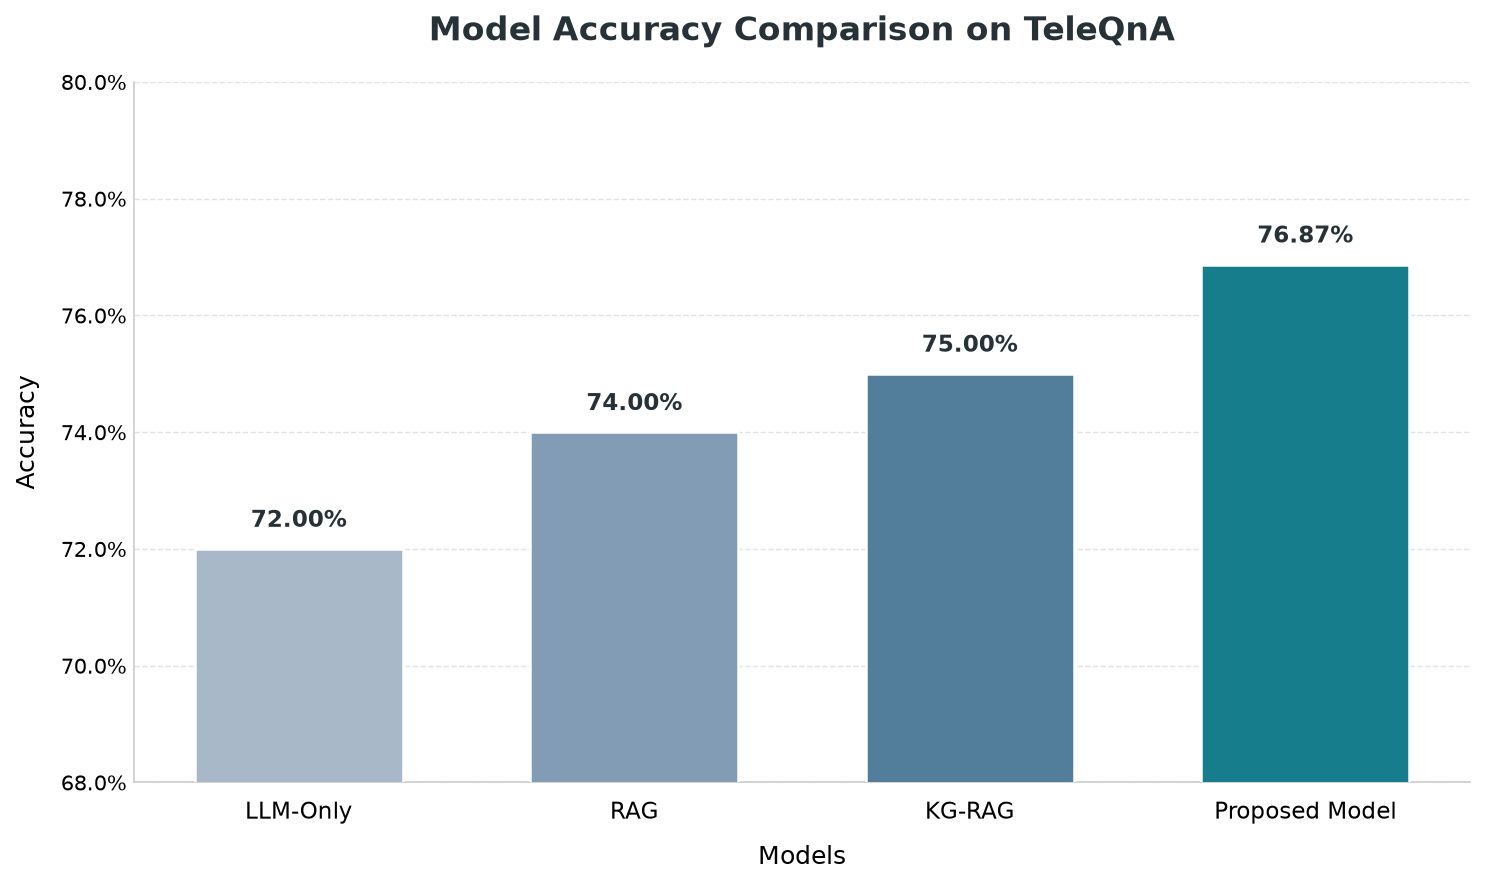

In [316]:
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick

models = ["LLM-Only", "RAG", "KG-RAG", "Proposed Model"]
accuracies = [0.72, 0.74, 0.75, 0.7687]

fig, ax = plt.subplots(figsize=(10, 6), dpi=150)

# Professional color palette
colors = ["#A9B8C8", "#829CB5", "#527D9B", "#167D8D"]

bars = ax.bar(
    models,
    accuracies,
    color=colors,
    edgecolor="white",
    linewidth=1.2,
    width=0.62,
    zorder=3
)

# Accuracy labels
ax.bar_label(
    bars,
    labels=[f"{v:.2%}" for v in accuracies],
    padding=8,
    fontsize=11,
    fontweight="bold",
    color="#263238"
)

# Titles and axis labels
ax.set_title(
    "Model Accuracy Comparison on TeleQnA",
    fontsize=16,
    fontweight="bold",
    pad=20,
    color="#263238"
)

ax.set_xlabel("Models", fontsize=12, labelpad=10)
ax.set_ylabel("Accuracy", fontsize=12, labelpad=10)

# Format y-axis as percentages
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0))
ax.set_ylim(0.68, 0.80)
ax.set_yticks([0.68, 0.70, 0.72, 0.74, 0.76, 0.78, 0.80])

# Subtle horizontal gridlines
ax.grid(axis="y", linestyle="--", linewidth=0.7, alpha=0.35, zorder=0)
ax.set_axisbelow(True)

# Remove unnecessary borders
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.spines["left"].set_color("#CCCCCC")
ax.spines["bottom"].set_color("#CCCCCC")

ax.tick_params(axis="x", labelsize=11, length=0, pad=9)
ax.tick_params(axis="y", labelsize=10, length=0)

plt.tight_layout()
plt.savefig("teleqna_accuracy_comparison.png", dpi=300, bbox_inches="tight")
plt.show()


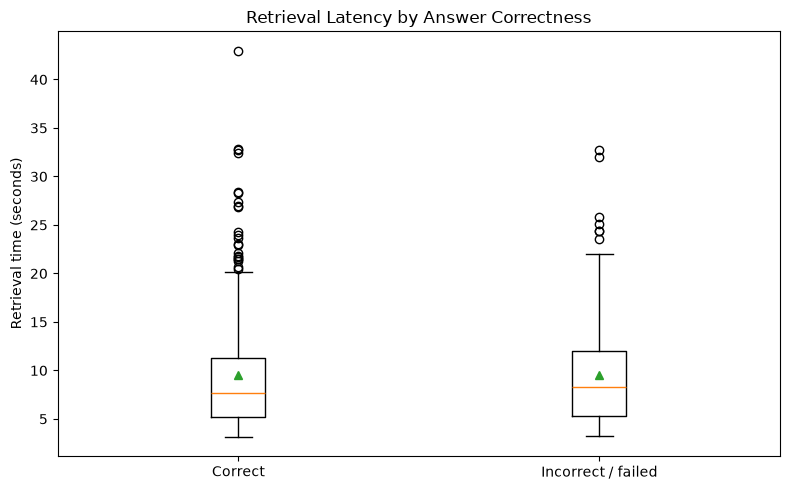

In [ ]:
eval_df["correct"] = ((eval_df["answer"] == eval_df["predictions"]))
plot_eval_df = eval_df[eval_df["retrieval_time"].notna() & (eval_df["retrieval_time"] >= 0)].copy()

correct_times = plot_eval_df.loc[plot_eval_df["correct"], "retrieval_time"]
incorrect_times = plot_eval_df.loc[~plot_eval_df["correct"], "retrieval_time"]

plt.figure(figsize=(8, 5))
plt.boxplot(
    [correct_times, incorrect_times],
    tick_labels=["Correct", "Incorrect / failed"],
    showmeans=True
)
plt.ylabel("Retrieval time (seconds)")
plt.title("Retrieval Latency by Answer Correctness")
plt.tight_layout()
plt.show()


## Latency

In [119]:
q3=eval_final['retrieval_time'].quantile(0.75)
q1=eval_final['retrieval_time'].quantile(0.25)
iqr=q3-q1
latency_df=eval_final[(eval_final['retrieval_time']<=(1.5*iqr+q3)) & (eval_final['retrieval_time']>0)]

In [120]:
latency_df.describe()

,Unnamed: 0,predictions,retrieval_time
count,425.000000,425.000000,425.000000
mean,656.712941,2.672941,8.317449
std,128.367002,1.336656,4.052783
min,438.000000,0.000000,3.172501
25%,547.000000,1.000000,5.109270
50%,653.000000,3.000000,7.524769
75%,764.000000,4.000000,10.481907
max,891.000000,5.000000,20.663741


In [312]:
plot_df = latency_df.copy()
TIME_COL = "retrieval_time"
TRUE_COL = "answer"
PRED_COL = "prediction"

plot_df[TIME_COL] = pd.to_numeric(plot_df[TIME_COL], errors="coerce")
valid_times = plot_df.loc[
    plot_df[TIME_COL].notna() & (plot_df[TIME_COL] >= 0), TIME_COL
]

print(f"Total questions: {len(plot_df)}")
print(f"Valid latency records: {len(valid_times)}")
print(f"Missing/invalid latency records: {len(plot_df) - len(valid_times)}")

if len(valid_times):
    print(f"Mean latency: {valid_times.mean():.4f} seconds")
    print(f"Median latency: {valid_times.median():.4f} seconds")
    print(f"P95 latency: {np.percentile(valid_times, 95):.4f} seconds")
    print(f"P99 latency: {np.percentile(valid_times, 99):.4f} seconds")

Total questions: 472
Valid latency records: 472
Missing/invalid latency records: 0
Mean latency: 8.2814 seconds
Median latency: 7.4471 seconds
P95 latency: 17.2100 seconds
P99 latency: 20.0695 seconds


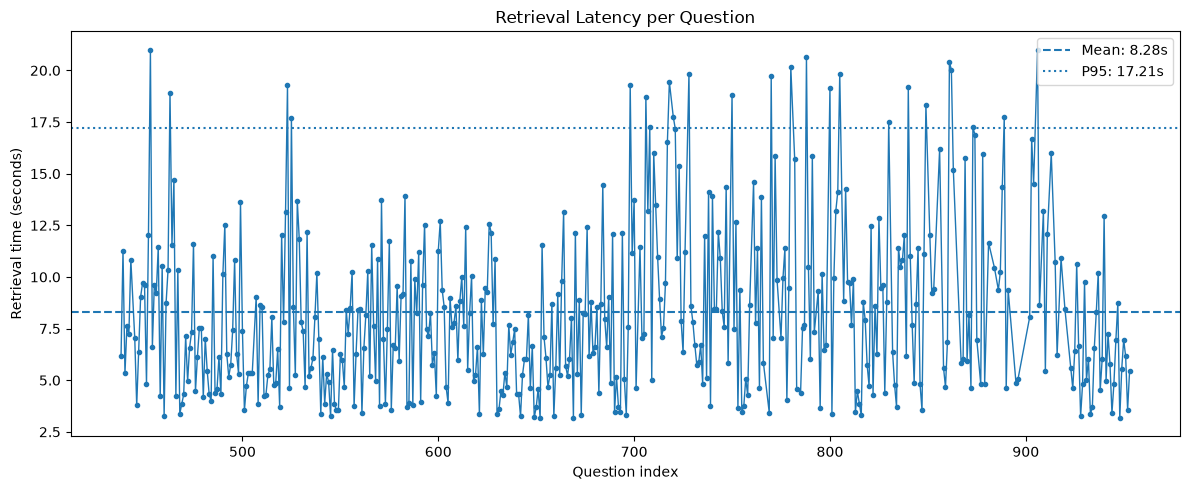

In [313]:

if len(valid_times):
    plt.figure(figsize=(12, 5))
    plt.plot(valid_times.index, valid_times.values, marker=".", linewidth=1)
    plt.axhline(valid_times.mean(), linestyle="--",
                label=f"Mean: {valid_times.mean():.2f}s")
    plt.axhline(np.percentile(valid_times, 95), linestyle=":",
                label=f"P95: {np.percentile(valid_times, 95):.2f}s")

    plt.xlabel("Question index")
    plt.ylabel("Retrieval time (seconds)")
    plt.title("Retrieval Latency per Question")
    plt.legend()
    plt.tight_layout()
    plt.show()


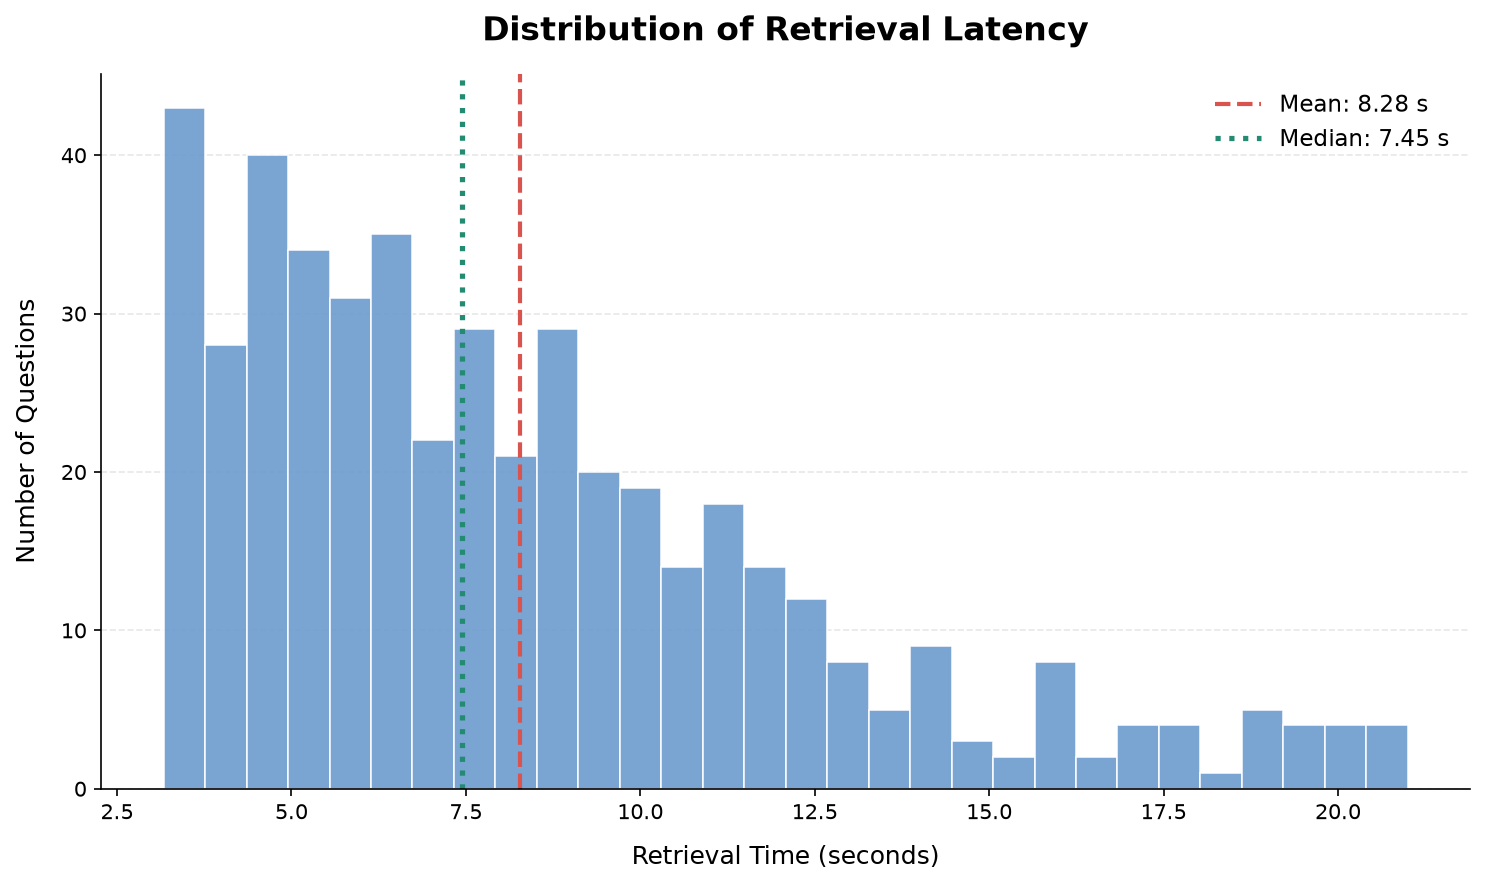

In [317]:
import matplotlib.pyplot as plt
import numpy as np

if len(valid_times):
    mean_time = np.mean(valid_times)
    median_time = np.median(valid_times)

    fig, ax = plt.subplots(figsize=(10, 6), dpi=150)

    # Histogram
    ax.hist(
        valid_times,
        bins=30,
        color="#6C9BCF",
        edgecolor="white",
        linewidth=0.8,
        alpha=0.9
    )

    # Mean and median
    ax.axvline(
        mean_time,
        color="#D9534F",
        linestyle="--",
        linewidth=2,
        label=f"Mean: {mean_time:.2f} s"
    )

    ax.axvline(
        median_time,
        color="#238B72",
        linestyle=":",
        linewidth=2.5,
        label=f"Median: {median_time:.2f} s"
    )

    # Titles and labels
    ax.set_title(
        "Distribution of Retrieval Latency",
        fontsize=16,
        fontweight="bold",
        pad=16
    )
    ax.set_xlabel("Retrieval Time (seconds)", fontsize=12, labelpad=10)
    ax.set_ylabel("Number of Questions", fontsize=12, labelpad=10)

    # Styling
    ax.grid(axis="y", linestyle="--", alpha=0.3)
    ax.set_axisbelow(True)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

    ax.legend(frameon=False, fontsize=11)
    ax.tick_params(axis="both", labelsize=10)

    plt.tight_layout()
    plt.savefig("retrieval_latency_distribution.png",
                dpi=300, bbox_inches="tight")
    plt.show()


In [125]:
eval_final

,Unnamed: 0,question_id,question,option 1,option 2,option 3,option 4,option 5,category,predictions,retrieval_time
0,0,question 0,What is the purpose of the Nmfaf_3daDataManage...,To configure the MFAF to map data or analytics...,To configure the MFAF to stop mapping data or ...,To supply data or analytics from the MFAF to n...,To fetch data or analytics from the MFAF based...,NaN,Standards specifications,2,NaN
1,1,question 4,How does a supporting UE attach to the same co...,It requests the core network node to remember ...,It uses information stored in the UE when it w...,It relies on the SIM/USIM card for information.,It performs a fresh attach procedure.,NaN,Standards specifications,4,NaN
2,2,question 11,When can the setting of the Privacy exception ...,Never,Only during emergency services,Anytime,Only with operator permission,NaN,Standards specifications,3,NaN
3,3,question 12,What does the NEF notify to the AF after deter...,AF Identifier,EAS address information,DNN,DNAI(s) or the updated DNAI information,NaN,Standards specifications,4,NaN
4,4,question 14,"In online charging, how are chargeable events ...",By the CTF,By the OCF,By the CGF,By the CHF,NaN,Standards specifications,1,NaN
...,...,...,...,...,...,...,...,...,...,...,...
1444,1504,question 9962,What criteria may be considered for evaluating...,Serving eNB.,Channel conditions.,QoS requirements.,Service type.,All of the above.,Standards specifications,5,NaN
1445,1505,question 9974,What is the purpose of Analytics/ML Model Accu...,To collect ground truth data for ML models,To compare predictions with ground truth data,To provide analytics accuracy information to c...,To determine ML Model degradation,NaN,Standards specifications,2,NaN
1446,1506,question 9986,What functions are included in the Online Char...,Online Charging Function (OCF) and Account Bal...,Charging Trigger Function (CTF) and Charging D...,Charging Trigger Function (CTF) and Charging G...,Session Based Charging Function (SBCF) and Eve...,Charging Data Function (CDF) and Rating Functi...,Standards specifications,1,NaN
1447,1507,question 9992,How is the SDT procedure initiated? [3GPP Rele...,Via a transmission over RACH or over Type 1 CG...,Via a transmission over SSB (Synchronization S...,Via a transmission over PDCCH (Physical Downli...,Via a transmission over MAC (Medium Access Con...,Via a transmission over PUSCH (Physical Uplink...,Standards specifications,1,NaN


## Number of Relationships

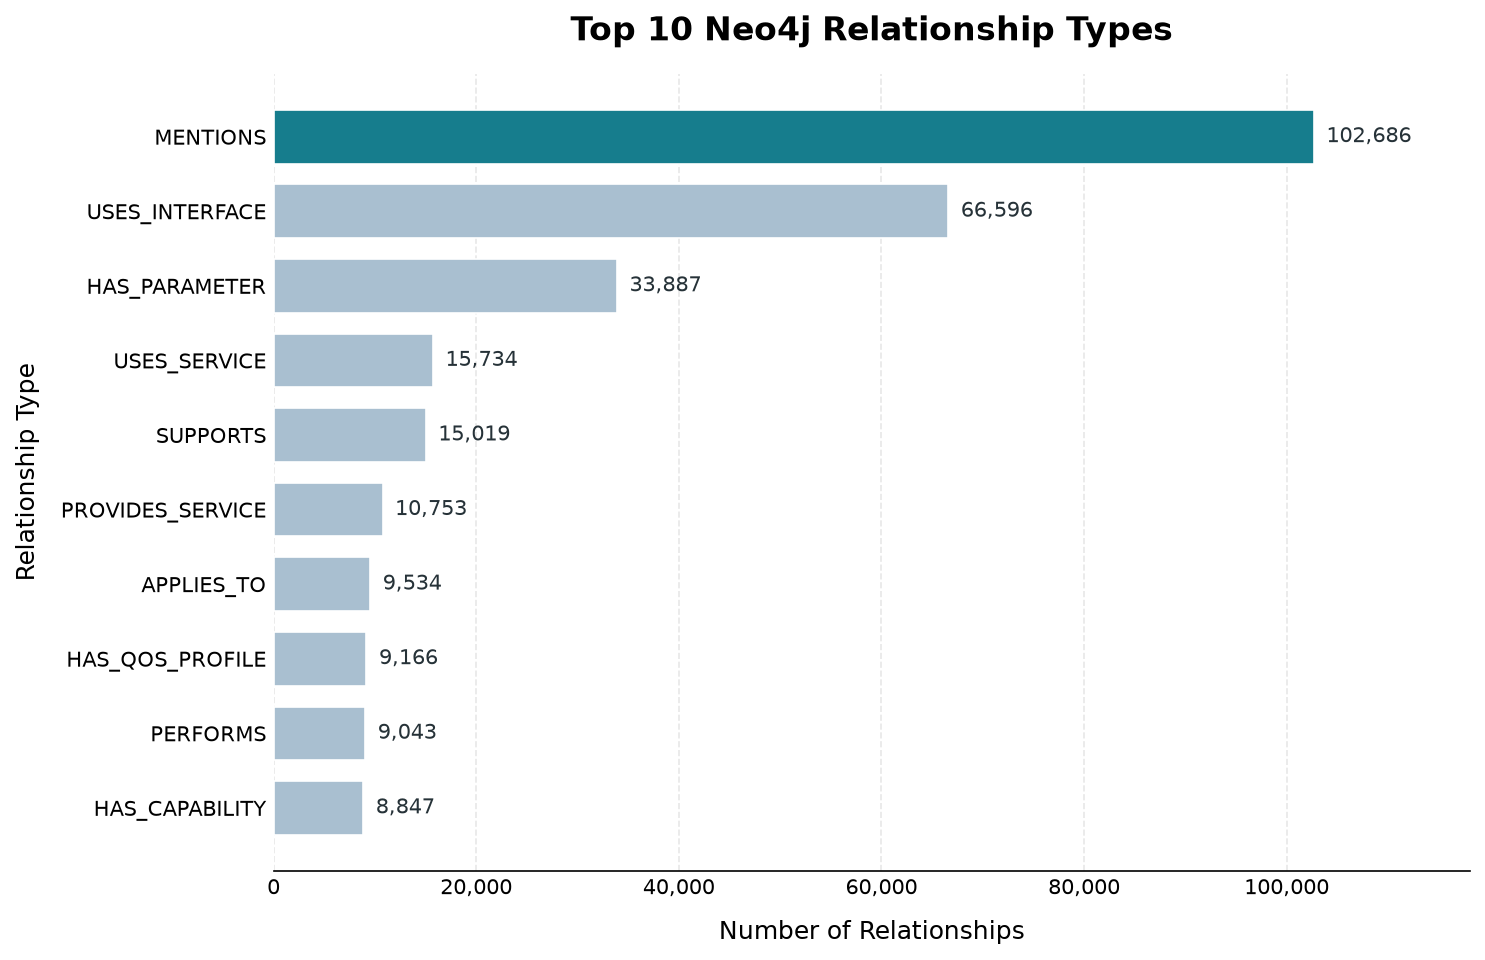

In [318]:
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick

relationship_types = [
    "MENTIONS", "USES_INTERFACE", "HAS_PARAMETER", "USES_SERVICE",
    "SUPPORTS", "PROVIDES_SERVICE", "APPLIES_TO",
    "HAS_QOS_PROFILE", "PERFORMS", "HAS_CAPABILITY"
]

relationship_counts = [
    102686, 66596, 33887, 15734, 15019,
    10753, 9534, 9166, 9043, 8847
]

# Sort in ascending order for a horizontal bar chart
sorted_data = sorted(
    zip(relationship_types, relationship_counts),
    key=lambda item: item[1]
)

labels = [item[0] for item in sorted_data]
counts = [item[1] for item in sorted_data]

fig, ax = plt.subplots(figsize=(10, 6.5), dpi=150)

# Highlight the most frequent relationship
colors = ["#A9BFD0"] * (len(counts) - 1) + ["#167D8D"]

bars = ax.barh(
    labels,
    counts,
    color=colors,
    edgecolor="white",
    linewidth=0.8,
    height=0.72,
    zorder=3
)

# Add relationship counts
ax.bar_label(
    bars,
    labels=[f"{value:,}" for value in counts],
    padding=6,
    fontsize=10,
    color="#263238"
)

# Titles and axis labels
ax.set_title(
    "Top 10 Neo4j Relationship Types",
    fontsize=16,
    fontweight="bold",
    pad=16
)

ax.set_xlabel("Number of Relationships", fontsize=12, labelpad=10)
ax.set_ylabel("Relationship Type", fontsize=12, labelpad=10)

# Grid and axis formatting
ax.set_xlim(0, max(counts) * 1.15)
ax.xaxis.set_major_formatter(
    plt.FuncFormatter(lambda x, _: f"{x:,.0f}")
)
ax.grid(axis="x", linestyle="--", alpha=0.3, zorder=0)
ax.set_axisbelow(True)

# Clean appearance
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.spines["left"].set_visible(False)
ax.tick_params(axis="y", length=0, labelsize=10)
ax.tick_params(axis="x", length=0, labelsize=10)

plt.tight_layout()

plt.savefig(
    "neo4j_relationship_types.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


In [328]:
'Accuracies of Different Models on TeleQnA Dataset'.upper()

'ACCURACIES OF DIFFERENT MODELS ON TELEQNA DATASET'